# 07 · Live Test and Tracker v3

The final model from notebook 06 (hybrid: event tracker v2 + Model A) was run **live**: the meter streamed to a
laptop over USB, Tera Term logged the serial output and `realtime/live_predict.py` predicted the appliance states as
the data arrived. The operator switched the 200 W bulb, the 100 W bulb and the hair straightener in various
combinations for about 7 minutes and confirmed the switching sequence afterwards (`data/live/`).

This is the **first fully independent test**: none of the data had been seen before.

In [1]:
import sys, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from sklearn.tree import export_text

sys.path.insert(0, str(Path.cwd().parent))
from src.config import APPLIANCES, APPLIANCE_NAMES, FIGURES_DIR, MODELS_DIR
from src.data_loader import load_labelled, load_events
from src.features import build_features, FEATURE_SETS
from src.evaluation import score, labels_to_combo
from src.models import build_from_params
from src.event_model import (block_sequences, event_training_table, make_tracker, event_features, clean_pf,
                             EVENT_FEATURES, EVENT_CLASSIFIERS, COMBOS, combo_index)
from src.hybrid import ModelACorrector

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIGURES_DIR / f"{name}.png")
ROOT = Path.cwd().parent
COLORS = {"hair_dryer": "#d62728", "hair_straightener": "#9467bd", "bulb_200W": "#ff7f0e", "bulb_100W": "#2ca02c"}
SHORT = {"hair_dryer": "Dryer", "hair_straightener": "Straightener", "bulb_200W": "200W", "bulb_100W": "100W"}

df = load_labelled()
events = load_events()
seqs = block_sequences(df)
table = event_training_table(seqs, events, max_lag=3)
train_df, train_table = df[df.split == "train"], table[table.block != "F_test"]
test_seq = seqs["F_test"]

live = pd.read_csv(ROOT / "data" / "live" / "live_session_1.csv")
live_events = pd.read_csv(ROOT / "data" / "live" / "live_session_1_events.csv")
# The console output used for this session shows power and PF but not current. Current is only used by Model A
# (start-up / corrections of the hybrid), so it is approximated from power, PF and a typical 246 V mains voltage.
live["current_A"] = np.where(live.power_W.abs() > 15, live.power_W.abs() / (246 * live.pf.clip(0.5, 1)), 0.098)
y_live = live[APPLIANCES].to_numpy(int)
print(f"Live session: {len(live)} samples ({len(live) * 5 / 60:.1f} min), {len(live_events)} switches")
live_events

Live session: 85 samples (7.1 min), 17 switches


,counter,appliance,action,session
0,1390,200W bulb,ON,live_2026-11-22
1,1430,200W bulb,OFF,live_2026-11-22
2,1445,100W bulb,ON,live_2026-11-22
3,1460,100W bulb,OFF,live_2026-11-22
4,1470,Hair straightener,ON,live_2026-11-22
5,1495,100W bulb,ON,live_2026-11-22
6,1520,200W bulb,ON,live_2026-11-22
7,1545,200W bulb,OFF,live_2026-11-22
8,1560,Hair straightener,OFF,live_2026-11-22
9,1600,100W bulb,OFF,live_2026-11-22


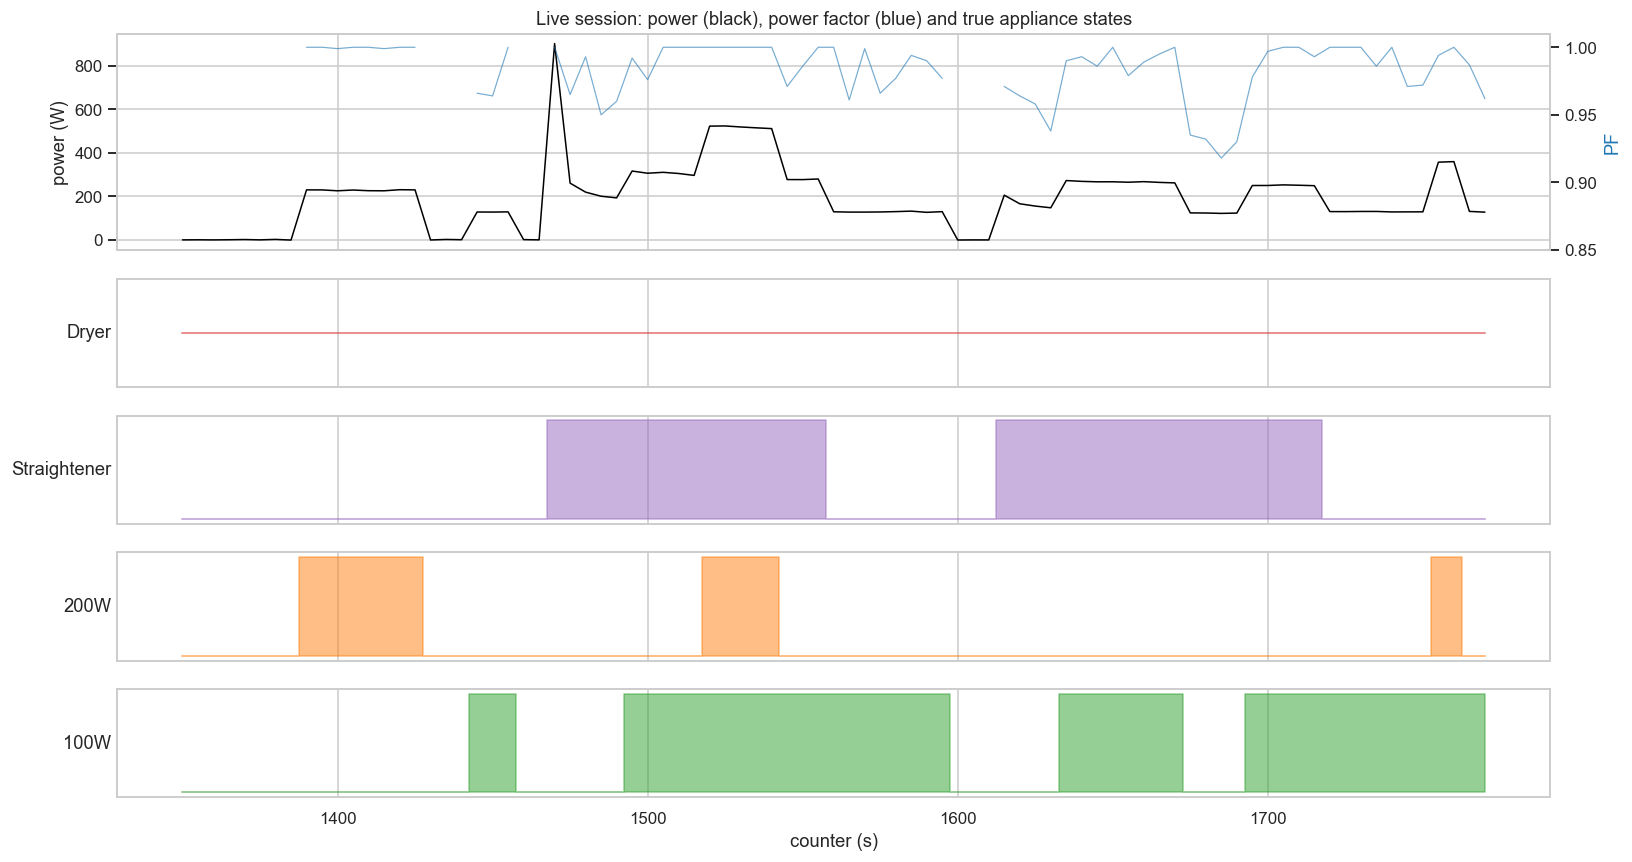

In [2]:
fig, axes = plt.subplots(5, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1, 1, 1]})
t = live.counter.values
axes[0].plot(t, live.power_W, color="black", lw=1); axes[0].set_ylabel("power (W)")
ax2 = axes[0].twinx(); ax2.plot(t, live.pf.where(live.power_W > 15), color="tab:blue", lw=0.8, alpha=0.6)
ax2.set_ylabel("PF", color="tab:blue"); ax2.set_ylim(0.85, 1.01); ax2.grid(False)
axes[0].set_title("Live session: power (black), power factor (blue) and true appliance states")
for k, a in enumerate(APPLIANCES):
    axes[k + 1].fill_between(t, 0, y_live[:, k], step="mid", color=COLORS[a], alpha=0.5)
    axes[k + 1].set_yticks([]); axes[k + 1].set_ylabel(SHORT[a], rotation=0, ha="right", va="center")
axes[-1].set_xlabel("counter (s)")
fig.tight_layout(); save(fig, "38_live_session"); plt.show()

## 1. The v2 final model on the live session

In [3]:
final_v2 = json.loads((MODELS_DIR / "final_model_v2.json").read_text())   # final model as selected in notebook 06
meta_a, meta_b2 = final_v2["model_a"], final_v2["model_b"]

def model_a_corrector():
    parts = []
    for b, s in seqs.items():
        if b == "F_test":
            continue
        F = build_features(s.assign(source_file="seq"), group_col="source_file")
        parts.append(pd.concat([s, F.drop(columns=["power_W", "current_A", "pf"])], axis=1))
    tr = pd.concat(parts, ignore_index=True)
    cols = FEATURE_SETS[meta_a["feature_set"]]
    m = build_from_params(meta_a["model"], meta_a["params"], "combo").fit(tr[cols], labels_to_combo(tr[APPLIANCES].to_numpy()))
    return ModelACorrector(m, cols)

corrector = model_a_corrector()
hyb_v2 = make_tracker(optuna.trial.FixedTrial(meta_b2["params"]), meta_b2["classifier"], train_df, train_table,
                      corrector=corrector, version=2)
pred_v2 = hyb_v2.run(live)
print(f"Live exact match (all 4 correct), v2 hybrid: {score(y_live, pred_v2)['exact_match']:.3f}")
wrong = np.where((pred_v2 != y_live).any(axis=1))[0]
pd.DataFrame({"counter": live.counter.values[wrong], "power_W": live.power_W.values[wrong],
              "predicted": labels_to_combo(pred_v2[wrong]), "true": labels_to_combo(y_live[wrong])})

Live exact match (all 4 correct), v2 hybrid: 0.753


,counter,power_W,predicted,true
0,1470,902.7,1000,0100
1,1560,129.7,0100,0001
2,1565,128.3,0100,0001
3,1570,128.3,0100,0001
4,1575,128.9,0100,0001
5,1580,130.5,0100,0001
6,1585,132.7,0100,0001
7,1590,127.2,0100,0001
8,1595,130.3,0100,0001
9,1615,206.1,0010,0100


The live score drops to ≈ 0.75 (state code = dryer, straightener, 200 W, 100 W). Nearly all errors come from two
moments, **1560** and **1720**: the **straightener was switched OFF while the 100 W bulb stayed ON**, and the
model switched the bulb off instead. The wrong state then lasted until the next switch.

## 2. Why: what the v2 event classifier actually learned

In [4]:
print(export_text(hyb_v2.clf, feature_names=EVENT_FEATURES))
P, PFc = live.power_W.to_numpy(), clean_pf(live.power_W, live.pf)
rows = []
for c, truth in [(1560, "straightener OFF"), (1675, "100 W bulb OFF"), (1720, "straightener OFF")]:
    i = int(np.where(live.counter == c)[0][0])
    f = event_features(P, PFc, i, i + hyb_v2.lag)
    pr = hyb_v2.clf.predict_proba(pd.DataFrame([f], columns=EVENT_FEATURES))[0]
    rows.append({"counter": c, "true switch": truth, "step_W": round(f[0], 1), "surge_W": round(f[2], 1),
                 "P(straightener)": round(pr[1], 3), "P(100 W bulb)": round(pr[3], 3)})
pd.DataFrame(rows)

|--- abs_step_W <= 870.30
|   |--- abs_step_W <= 180.65
|   |   |--- surge_W <= 24.00
|   |   |   |--- class: 3
|   |   |--- surge_W >  24.00
|   |   |   |--- class: 1
|   |--- abs_step_W >  180.65
|   |   |--- surge_W <= 32.20
|   |   |   |--- class: 2
|   |   |--- surge_W >  32.20
|   |   |   |--- class: 1
|--- abs_step_W >  870.30
|   |--- step_W <= 1506.60
|   |   |--- class: 0
|   |--- step_W >  1506.60
|   |   |--- class: 0



,counter,true switch,step_W,surge_W,P(straightener),P(100 W bulb)
0,1560,straightener OFF,-151.5,0.8,0.315,0.685
1,1675,100 W bulb OFF,-138.7,0.8,0.315,0.685
2,1720,straightener OFF,-118.4,-0.7,0.315,0.685


The tuned v2 event classifier is a depth-3 decision tree that only uses the **size of the step** and the **surge**.
For an OFF step below ≈ 180 W without a surge it always answers *100 W bulb* (0.685 vs 0.315), whatever the power
factor. So whenever the straightener and the 100 W bulb are both ON and one of them switches off, v2 blames the
bulb. At 1675 that happened to be right, at 1560 and 1720 it was wrong.

**Why cross-validation and the test block did not reveal it:** the training data contains only 9 OFF switches of
this kind, and both such switches in the test block were the bulb, so the tree's default answer was right there.

In [5]:
prev = df[["run", "counter"] + APPLIANCES].copy(); prev["counter"] += 5
m = events.merge(prev, on=["run", "counter"], how="left")
amb = m[(m.action == "OFF") & m.appliance.isin(["Hair straightener", "100W bulb"])
        & (m.hair_straightener == 1) & (m.bulb_100W == 1)]
amb.groupby(["block"]).appliance.value_counts().unstack(fill_value=0)

appliance,100W bulb,Hair straightener
block,,
D_lookalike,1,0
E_tour1,2,1
E_tour2,1,1
E_tour3,0,1
E_tour4,1,1
F_test,2,0


## 3. Tracker v3: check what is left after an OFF switch

When an OFF switch could belong to more than one appliance, the readings **after** the switch reveal the answer:
the remaining appliances have a known signature. For each candidate, the mean power and mean power factor of the
samples after the switch are compared with the steady-state signature of the combination that would remain
(learned from the training data), and that fit is combined with the event classifier's vote:

`score(k) = log P_classifier(k) − fit_weight × NLL(readings after | combination without k)`

Averaging the samples after the switch matters: for small loads the meter's PF jumps by a few percent from sample to
sample (current is measured in ≈ 20 mA steps), so a single PF reading is unreliable but the mean is not.

In [6]:
prof = hyb_v2.profile
sig = pd.DataFrame(prof.sig_, columns=["P_mean", "P_sd", "PF_mean", "PF_sd"])
sig.index = [labels_to_combo([c])[0] for c in COMBOS]
sig.loc[["0001", "0100", "0010", "0011", "0110", "0101"]].round(3)

,P_mean,P_sd,PF_mean,PF_sd
0001,129.244,3.000,0.990,0.012
0100,123.031,21.274,0.963,0.019
0010,226.669,3.000,0.998,0.008
0011,353.216,3.719,0.996,0.008
0110,339.983,7.275,0.995,0.008
0101,262.000,32.034,0.994,0.008


In [7]:
rows = []
for c, truth in [(1560, "straightener OFF"), (1675, "100 W bulb OFF"), (1720, "straightener OFF")]:
    i = int(np.where(live.counter == c)[0][0]); s = i + hyb_v2.lag
    pm, fm = P[i + 1: s + 1].mean(), PFc[i + 1: s + 1].mean()
    before = y_live[i - 1]
    nll = {}
    for k, name in [(1, "straightener"), (3, "100 W bulb")]:
        rem = before.copy(); rem[k] = 0
        nll[name] = prof.signature_nll(combo_index(rem), pm, fm)
    rows.append({"counter": c, "true switch": truth, "mean P after": round(pm, 1), "mean PF after": round(fm, 3),
                 "NLL if straightener OFF": round(nll["straightener"], 2), "NLL if 100 W OFF": round(nll["100 W bulb"], 2),
                 "better fit": "straightener OFF" if nll["straightener"] < nll["100 W bulb"] else "100 W bulb OFF"})
pd.DataFrame(rows)

,counter,true switch,mean P after,mean PF after,NLL if straightener OFF,NLL if 100 W OFF,better fit
0,1560,straightener OFF,128.5,0.975,-2.51,-0.65,straightener OFF
1,1675,100 W bulb OFF,123.4,0.927,12.58,0.87,100 W bulb OFF
2,1720,straightener OFF,131.0,0.995,-3.07,0.64,straightener OFF


The fit to the remaining combination picks the right appliance in all three cases (lower NLL = better fit).

## 4. Re-tuning v3 (cross-validation only)

`fit_weight` (0 – 3) is added to the search space and all 7 event classifiers are re-tuned exactly as before
(`python scripts/tune_model_b.py --version 3`): leave-one-block-out CV on the training blocks, at least 100 trials,
stop after 30 without improvement. The weight is chosen by cross-validation, **not** by the live or test results.

In [8]:
V3_DIR = ROOT / "reports" / "model_b" / "v3"
res3 = pd.read_csv(V3_DIR / "tuning_results.csv")
res3["params"] = res3["best_params"].map(json.loads)
res3["fit_weight"] = res3["params"].map(lambda p: p.get("fit_weight", 0.0))
print(f"{len(res3)} studies, {int(res3.n_trials.sum()):,} trials")
res3[["classifier_name", "cv_exact_match", "fit_weight", "n_trials", "best_trial_number"]].round(3)

7 studies, 725 trials


,classifier_name,cv_exact_match,fit_weight,n_trials,best_trial_number
0,Decision Tree,0.963,2.272,100,60
1,Random Forest,0.962,2.089,100,45
2,XGBoost,0.960,1.030,112,81
3,SVM (RBF kernel),0.958,1.355,113,82
4,Logistic Regression,0.895,2.988,100,13
5,k-Nearest Neighbours,0.885,2.601,100,60
6,Nearest-centroid rule,0.790,2.759,100,51


## 5. v3 on the test block and on the live session

In [9]:
rows, fitted = [], {}
for r in res3.itertuples():
    trk = make_tracker(optuna.trial.FixedTrial(r.params), r.classifier, train_df, train_table, version=3)
    pt, pl = trk.run(test_seq), trk.run(live)
    rows.append({"classifier": r.classifier, "classifier_name": r.classifier_name, "fit_weight": r.fit_weight,
                 "cv_exact_match": r.cv_exact_match,
                 "test_exact_match": score(test_seq[APPLIANCES].to_numpy(int), pt)["exact_match"],
                 "live_exact_match": score(y_live, pl)["exact_match"]})
final3 = pd.DataFrame(rows).sort_values("cv_exact_match", ascending=False).reset_index(drop=True)
final3.to_csv(V3_DIR / "final_leaderboard.csv", index=False)
final3.round(3)

,classifier,classifier_name,fit_weight,cv_exact_match,test_exact_match,live_exact_match
0,decision_tree,Decision Tree,2.272,0.963,0.951,0.941
1,random_forest,Random Forest,2.089,0.962,0.989,0.941
2,xgboost,XGBoost,1.030,0.960,0.951,0.965
3,svm,SVM (RBF kernel),1.355,0.958,0.918,0.929
4,logistic_regression,Logistic Regression,2.988,0.895,0.934,0.929
5,knn,k-Nearest Neighbours,2.601,0.885,0.891,0.929
6,rule,Nearest-centroid rule,2.759,0.790,0.454,0.624


In [10]:
best3 = final3.iloc[0]
p3 = res3.set_index("classifier").loc[best3.classifier, "params"]
hyb_v3 = make_tracker(optuna.trial.FixedTrial(p3), best3.classifier, train_df, train_table,
                      corrector=corrector, version=3)
hyb_v2_test = hyb_v2.run(test_seq); hyb_v3_test = hyb_v3.run(test_seq)
hyb_v3_live = hyb_v3.run(live)
y_te = test_seq[APPLIANCES].to_numpy(int)

def cold_start(trk):
    vals = []
    for k in range(0, len(test_seq) - 30, 5):
        sub = test_seq.iloc[k:].reset_index(drop=True)
        vals.append((trk.run(sub) == sub[APPLIANCES].to_numpy(int)).all(axis=1).mean())
    return float(np.mean(vals))

cv_v2 = float(pd.read_csv(ROOT / "reports" / "model_b" / "tuning_results.csv").iloc[0].cv_exact_match)
comparison = pd.DataFrame({
    "Hybrid v2 (notebook 06)": [cv_v2, score(y_te, hyb_v2_test)["exact_match"], score(y_live, pred_v2)["exact_match"],
                                cold_start(hyb_v2)],
    f"Hybrid v3 ({best3.classifier_name})": [best3.cv_exact_match, score(y_te, hyb_v3_test)["exact_match"],
                                             score(y_live, hyb_v3_live)["exact_match"], cold_start(hyb_v3)],
}, index=["CV exact match", "Test exact match", "Live exact match", "Cold start on test (mean)"])
comparison.round(3)

,Hybrid v2 (notebook 06),Hybrid v3 (Decision Tree)
CV exact match,0.939,0.963
Test exact match,0.984,0.951
Live exact match,0.753,0.941
Cold start on test (mean),0.944,0.859


In [11]:
wrong = np.where((hyb_v3_live != y_live).any(axis=1))[0]
print("Remaining live errors (v3):")
pd.DataFrame({"counter": live.counter.values[wrong], "power_W": live.power_W.values[wrong],
              "predicted": labels_to_combo(hyb_v3_live[wrong]), "true": labels_to_combo(y_live[wrong]),
              "right after a switch": [int(c) in set(live_events.counter) or int(c) - 5 in set(live_events.counter)
                                       or int(c) - 10 in set(live_events.counter) for c in live.counter.values[wrong]]})

Remaining live errors (v3):


,counter,power_W,predicted,true,right after a switch
0,1470,902.7,1000,0100,True
1,1560,129.7,0100,0001,True
2,1565,128.3,0100,0001,True
3,1615,206.1,0010,0100,True
4,1720,130.6,0100,0001,True


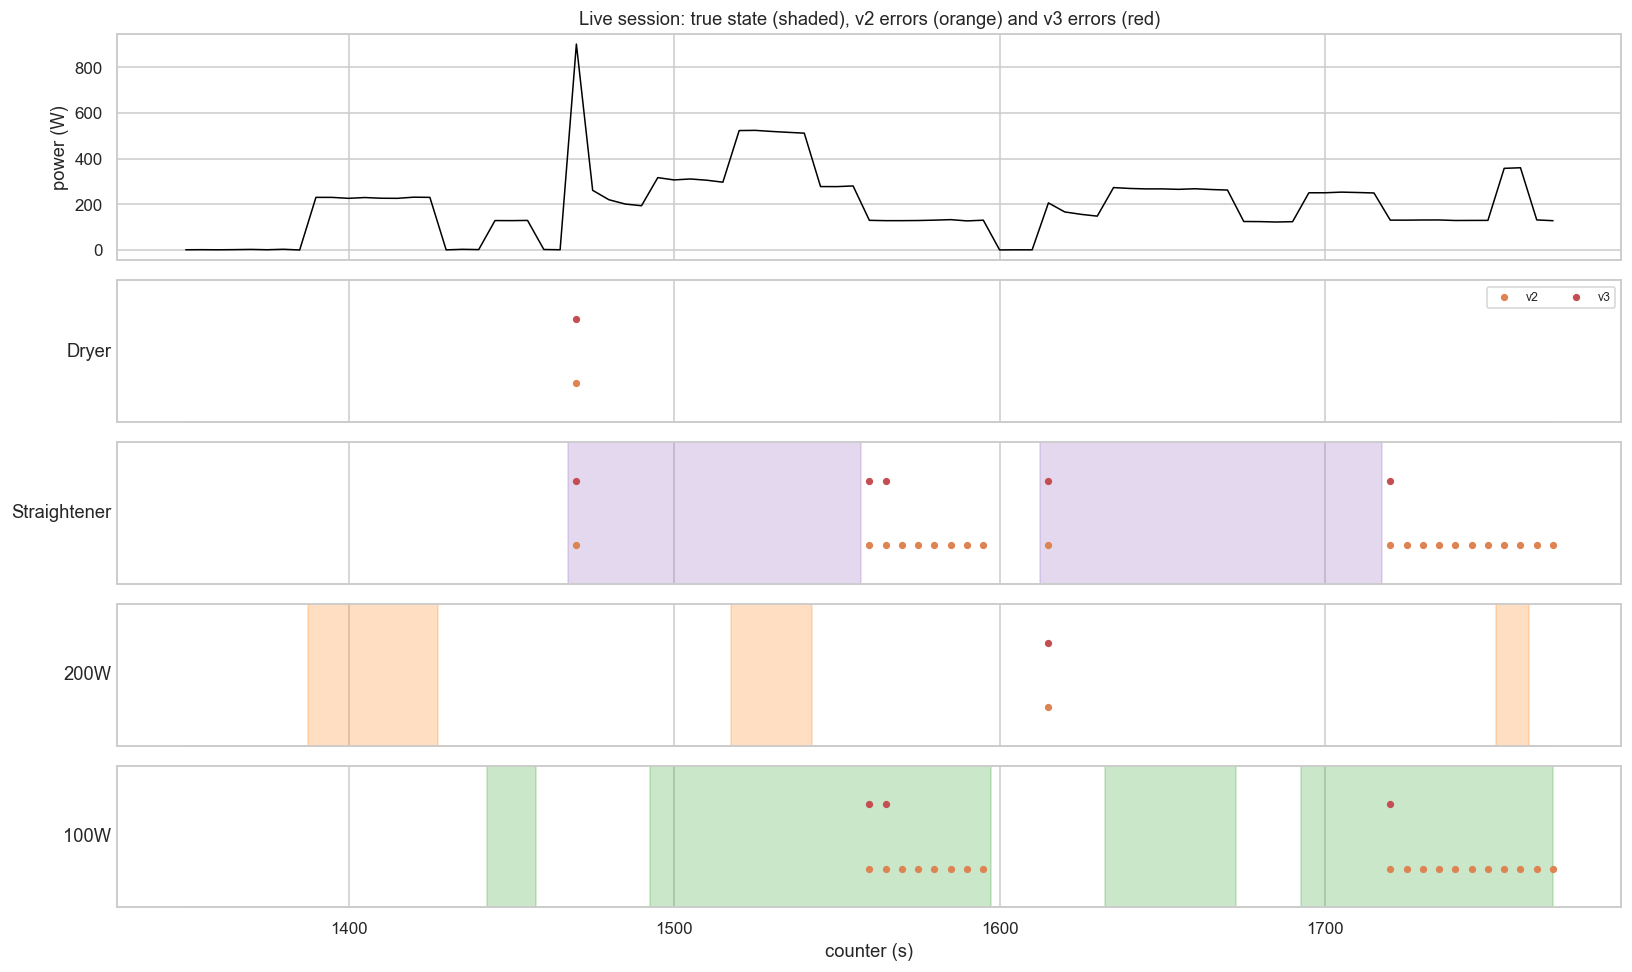

In [12]:
fig, axes = plt.subplots(5, 1, figsize=(15, 9), sharex=True, gridspec_kw={"height_ratios": [1.6, 1, 1, 1, 1]})
t = live.counter.values
axes[0].plot(t, live.power_W, color="black", lw=1); axes[0].set_ylabel("power (W)")
axes[0].set_title("Live session: true state (shaded), v2 errors (orange) and v3 errors (red)")
for k, a in enumerate(APPLIANCES):
    ax = axes[k + 1]
    ax.fill_between(t, 0, y_live[:, k] * 2.2, step="mid", color=COLORS[a], alpha=0.25)
    for j, (pred, col, name) in enumerate([(pred_v2, "#dd8452", "v2"), (hyb_v3_live, "#c44e52", "v3")]):
        w_ = pred[:, k] != y_live[:, k]
        ax.scatter(t[w_], np.full(w_.sum(), 0.6 + j), color=col, s=14, label=name if k == 0 else None)
    ax.set_ylim(0, 2.2); ax.set_yticks([]); ax.set_ylabel(SHORT[a], rotation=0, ha="right", va="center")
axes[1].legend(loc="upper right", fontsize=8, ncol=2)
axes[-1].set_xlabel("counter (s)")
fig.tight_layout(); save(fig, "39_live_v2_vs_v3"); plt.show()

## 6. Update the final model

In [13]:
SELECT_V3 = comparison.loc["CV exact match"].iloc[1] >= comparison.loc["CV exact match"].iloc[0]
print("Select v3 (by CV):", SELECT_V3)
if SELECT_V3:
    new_meta = dict(final_v2)
    new_meta.update({
        "name": "Hybrid (B v3 + A)",
        "description": "Event-based tracker v3 (with the remaining-combination check for OFF switches) whose start-up "
                       "state and power-sum corrections come from Model A",
        "tracker_version": 3,
        "model_b": {"classifier": best3.classifier, "classifier_name": best3.classifier_name, "params": p3,
                    "event_features": EVENT_FEATURES, "cv_exact_match": float(best3.cv_exact_match)},
        "scores": {"cv_exact_match": float(best3.cv_exact_match),
                   "test_exact_match": float(comparison.iloc[1, 1]),
                   "live_session_1_exact_match": float(comparison.iloc[2, 1]),
                   "cold_start_mean": float(comparison.iloc[3, 1])},
    })
    (MODELS_DIR / "final_model.json").write_text(json.dumps(new_meta, indent=2))
    print("models/final_model.json updated -> run `python scripts/build_final_model.py` to rebuild the model file")

Select v3 (by CV): True
models/final_model.json updated -> run `python scripts/build_final_model.py` to rebuild the model file


## Summary

**What the live test showed.** The v2 hybrid reached only **0.753** on the live session. Both large errors were the
same situation: the **straightener switched OFF while the 100 W bulb stayed ON**. The tuned v2 event classifier
only looked at step size and surge and always blamed the bulb for small OFF steps. Training contained just 9 such
switches, and both in the test block happened to be the bulb, so neither CV nor the test block exposed it.

**Tracker v3** checks *what is left* after an OFF switch that could belong to more than one appliance: the mean power
and power factor after the switch are compared with the learned signature of each possible remaining combination.
It was re-tuned and selected by cross-validation only.

| | Hybrid v2 | **Hybrid v3 (new final model)** |
|---|---|---|
| CV exact match | 0.939 | **0.963** |
| Live session exact match | 0.753 | **0.941** |
| Test exact match | 0.984 | 0.951 |
| Start-up mid-use (test, mean) | 0.944 | 0.859 |

- On the live session **every switch is identified correctly once it has settled**. The remaining live errors are
  the provisional answers in the first seconds after a switch.
- On the test block v3 makes one new mistake: the 100 W bulb switched off while a *hot* straightener (≈ 120 W, PF
  close to the bulb's) stayed on, 10 s after the dryer switched off; v3 attributes it to the straightener. The same
  mistake falls inside many of the start-up runs, which is why that score drops.
- v3 is selected because cross-validation prefers it, and it fixes a failure seen in real use, at the cost of one
  genuinely ambiguous case.

**Honesty note.** The live session prompted the v3 change, so its 0.941 is no longer an independent estimate. The
next step is a **second live session**, ideally including straightener-OFF while bulbs are on, the dryer, and some
quick successive switches, scored without changing the model.